<a href="https://colab.research.google.com/github/atelerix-jpg/Python_Fundamentals_Final/blob/main/Antarctica_Climate_Analysis_Jacquelyn_Smith.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [149]:
import pandas as pd
df = pd.read_csv('antarctica_climate_2006_2025.csv')

10/23/2026 - Checking for null values using string function "info". No null values in the data, and all columns show a single data type.

In [150]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36525 entries, 0 to 36524
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         36525 non-null  object 
 1   location                     36525 non-null  object 
 2   latitude                     36525 non-null  float64
 3   longitude                    36525 non-null  float64
 4   weather_code                 36525 non-null  int64  
 5   temperature_2m_mean          36525 non-null  float64
 6   temperature_2m_max           36525 non-null  float64
 7   temperature_2m_min           36525 non-null  float64
 8   precipitation_sum            36525 non-null  float64
 9   rain_sum                     36525 non-null  float64
 10  precipitation_hours          36525 non-null  float64
 11  wind_speed_10m_max           36525 non-null  float64
 12  wind_gusts_10m_max           36525 non-null  float64
 13  wind_direction_1

10/23/2026 - Checking for duplicate values in the data using string functions "duplicated" and "value_counts". No duplicate values in the data.

In [151]:
df.duplicated().value_counts()

,count
False,36525


10/23/2026 - Checking for standardization of locations, latitudes, and longitudes with "value_counts". Any that are not floats would result in errors. All are standardized.

In [152]:
df[['location', 'latitude', 'longitude']].value_counts()

,,,count
location,latitude,longitude,
Antarctic_Peninsula,-64.7742,-62.8752,7305
East_Antarctica,-82.8628,75.0000,7305
McMurdo,-77.8419,166.6863,7305
South_Pole,-90.0000,0.0000,7305
West_Antarctica,-82.8628,-135.0000,7305


10/23/2026 - Checking for negative wind speeds and precipitations - these cannot be negative and would require changing to positive. There are no negative precipitation or wind values.

In [153]:
df.loc[(df['precipitation_sum'] < 0) | (df['rain_sum'] < 0) | (df['precipitation_hours'] < 0) | (df['wind_speed_10m_max'] < 0) | (df['wind_gusts_10m_max'] < 0)]

,date,location,latitude,longitude,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration


10/23/2026 - Checking z-scores of temperatures, precipitation, and wind speed for each location to detect outliers. Tested average temperatures, total precipitation, total rain, hours of precipitation, wind speed, and wind gusts for outliers. None detected.

In [154]:
temp_mean_avg = df.groupby('location')['temperature_2m_mean'].mean()
temp_std_avg = df.groupby('location')['temperature_2m_mean'].std()
df['temp_avg_z-score'] = (df['temperature_2m_mean'] - temp_mean_avg) / temp_std_avg

df.loc[df['temp_avg_z-score'] > 3]

,date,location,latitude,longitude,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,temp_avg_z-score


In [155]:
precipitation_avg = df.groupby('location')['precipitation_sum'].mean()
precipitation_std = df.groupby('location')['precipitation_sum'].std()
df['precipitation_z-score'] = (df['precipitation_sum'] - precipitation_avg) / precipitation_std

df.loc[df['precipitation_z-score'] > 3]

,date,location,latitude,longitude,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,temp_avg_z-score,precipitation_z-score


In [156]:
rain_avg = df.groupby('location')['rain_sum'].mean()
rain_std = df.groupby('location')['rain_sum'].std()
df['rain_z-score'] = (df['rain_sum'] - rain_avg) / rain_std

df.loc[df['rain_z-score'] > 3]

,date,location,latitude,longitude,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,temp_avg_z-score,precipitation_z-score,rain_z-score


In [157]:
precipitation_hrs_avg = df.groupby('location')['precipitation_hours'].mean()
precipitation_hrs_std = df.groupby('location')['precipitation_hours'].std()
df['precipitation_hrs_z-score'] = (df['precipitation_hours'] - precipitation_hrs_avg) / precipitation_hrs_std

df.loc[df['precipitation_hrs_z-score'] > 3]

,date,location,latitude,longitude,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,...,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,temp_avg_z-score,precipitation_z-score,rain_z-score,precipitation_hrs_z-score


In [158]:
wind_speed_avg = df.groupby('location')['wind_speed_10m_max'].mean()
wind_speed_std = df.groupby('location')['wind_speed_10m_max'].std()
df['wind_speed_z-score'] = (df['wind_speed_10m_max'] - wind_speed_avg) / wind_speed_std

df.loc[df['wind_speed_z-score'] > 3]

,date,location,latitude,longitude,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,...,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,temp_avg_z-score,precipitation_z-score,rain_z-score,precipitation_hrs_z-score,wind_speed_z-score


In [159]:
wind_gust_avg = df.groupby('location')['wind_gusts_10m_max'].mean()
wind_gust_std = df.groupby('location')['wind_gusts_10m_max'].std()
df['wind_gust_z-score'] = (df['wind_gusts_10m_max'] - wind_gust_avg) / wind_gust_std

df.loc[df['wind_gust_z-score'] > 3]

,date,location,latitude,longitude,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,...,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,temp_avg_z-score,precipitation_z-score,rain_z-score,precipitation_hrs_z-score,wind_speed_z-score,wind_gust_z-score


In [160]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

In [161]:
df_locations = pd.DataFrame({
    'Location': ['Antarctic_Peninsula', 'East_Antarctica', 'McMurdo', 'South_Pole', 'West_Antarctica'],
    'Lat': [-64.7742, -82.8628, -77.8419, -90.0000, -82.8628],
    'Lon': [-62.8752, 75.0000, 166.6863, 0.0000, -135.0000]
})

fig = px.scatter_geo(
    df_locations,
    lat = 'Lat',
    lon = 'Lon',
    hover_name = 'Location',
    projection = 'stereographic'
)

fig.update_geos(
    projection_rotation = dict(lat = -90, lon = 0, roll = 0),
    projection_scale = 0.45,
    lataxis_range = [-90, -65],
    showland = True,
    landcolor = 'lightgray',
    showocean = True,
    oceancolor = 'lightblue'
)

fig.update_layout(margin = dict(l = 0, r = 0, t = 40, b = 0))
fig.show()

In [162]:
df.groupby('location')[['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min']].describe()

temperature_2m_mean                                    \
                                  count       mean        std   min   25%   
location                                                                    
Antarctic_Peninsula              7305.0  -4.973717   5.178413 -26.2  -8.1   
East_Antarctica                  7305.0 -51.155496  10.881197 -75.3 -59.7   
McMurdo                          7305.0 -20.244476   9.421651 -48.5 -27.3   
South_Pole                       7305.0 -44.925654  10.336313 -68.6 -53.1   
West_Antarctica                  7305.0 -24.653196  10.839994 -59.0 -32.2   

                                      temperature_2m_max             ...  \
                      50%   75%   max              count       mean  ...   
location                                                             ...   
Antarctic_Peninsula  -3.6  -1.0   6.1             7305.0  -3.095346  ...   
East_Antarctica     -53.3 -41.9 -23.9             7305.0 -49.037194  ...   
McMurdo             -21.0 -12.4   0.1             7305.0 -17.401766  ...   
South_Pole          -46.7 -36.5 -17.3             7305.0 -43.364600  ...   
West_Antarctica     -24.6 -15.7  -0.8             7305.0 -21.888720  ...   

                                temperature_2m_min                        \
                      75%   max              count       mean        std   
location                                                                   
Antarctic_Peninsula   0.4   7.7             7305.0  -7.044887   5.673137   
East_Antarctica     -40.1 -22.3             7305.0 -53.548282  10.983775   
McMurdo             -10.1   0.7             7305.0 -22.895948   9.896916   
South_Pole          -35.4 -15.8             7305.0 -46.504230  10.688568   
West_Antarctica     -13.0   1.5             7305.0 -27.136920  11.162210   

                                                   
                      min   25%   50%   75%   max  
location                                           
Antarctic_Peninsula -27.8 -10.8  -5.8  -2.6   5.2  
East_Antarctica     -79.0 -62.0 -55.8 -44.2 -25.5  
McMurdo             -51.0 -30.4 -24.0 -14.6  -0.7  
South_Pole          -69.5 -55.1 -48.6 -37.8 -18.3  
West_Antarctica     -60.2 -35.2 -27.5 -18.0  -1.4  

[5 rows x 24 columns]

In the descriptive statistics for temperature, the Antarctic Peninsula regularly shows that it is warmer than any other location. Despite being the furthest south location, the South Pole is, on average, warmer than East Antarctica. This is further explored with a visual below.

In [163]:
df.groupby('location')[['precipitation_sum', 'rain_sum', 'precipitation_hours']].describe()

precipitation_sum                                          \
                                count      mean       std  min  25%  50%  75%   
location                                                                        
Antarctic_Peninsula            7305.0  5.778604  8.665887  0.0  0.0  1.9  8.2   
East_Antarctica                7305.0  0.000438  0.017970  0.0  0.0  0.0  0.0   
McMurdo                        7305.0  0.253101  0.928015  0.0  0.0  0.0  0.0   
South_Pole                     7305.0  0.038946  0.228893  0.0  0.0  0.0  0.0   
West_Antarctica                7305.0  0.084832  0.357113  0.0  0.0  0.0  0.0   

                          rain_sum            ...             \
                      max    count      mean  ...  75%   max   
location                                      ...              
Antarctic_Peninsula  81.9   7305.0  0.220739  ...  0.0  40.3   
East_Antarctica       1.0   7305.0  0.000014  ...  0.0   0.1   
McMurdo              17.3   7305.0  0.001916  ...  0.0   0.3   
South_Pole            3.3   7305.0  0.000821  ...  0.0   0.2   
West_Antarctica       7.4   7305.0  0.000849  ...  0.0   0.2   

                    precipitation_hours                                     \
                                  count      mean       std  min  25%  50%   
location                                                                     
Antarctic_Peninsula              7305.0  9.781109  8.986976  0.0  0.0  8.0   
East_Antarctica                  7305.0  0.004381  0.179699  0.0  0.0  0.0   
McMurdo                          7305.0  1.541958  4.180966  0.0  0.0  0.0   
South_Pole                       7305.0  0.369884  2.126818  0.0  0.0  0.0   
West_Antarctica                  7305.0  0.635044  2.349962  0.0  0.0  0.0   

                                 
                      75%   max  
location                         
Antarctic_Peninsula  18.0  24.0  
East_Antarctica       0.0  10.0  
McMurdo               0.0  24.0  
South_Pole            0.0  24.0  
West_Antarctica       0.0  24.0  

[5 rows x 24 columns]

In the descriptive statistics for precipitation, only one location seems to get a significant amount of precipitation - the Antarctic Peninsula. All other locations receive an average of less than 1cm precipitation per year. Because the amount of rain is quite low, it can be inferred that this precipitation tends to be in the form of snow, sleet, or hail.

In [164]:
df['sunshine_hrs'] = df['sunshine_duration'] / 3600
df['sunshine_hrs'] = df['sunshine_hrs'].round(2)
df.groupby('location')[['wind_speed_10m_max', 'wind_gusts_10m_max', 'sunshine_hrs']].describe()

wind_speed_10m_max                                         \
                                 count       mean        std  min   25%   50%   
location                                                                        
Antarctic_Peninsula             7305.0  23.903765   9.379264  3.9  17.1  23.3   
East_Antarctica                 7305.0  26.428679   8.391656  7.0  20.3  25.5   
McMurdo                         7305.0  16.945900   7.713534  3.4  11.3  15.1   
South_Pole                      7305.0  12.694086  12.308716  0.5   2.5   3.9   
West_Antarctica                 7305.0  25.767734  10.886976  3.3  17.8  23.6   

                                wind_gusts_10m_max             ...        \
                      75%   max              count       mean  ...   75%   
location                                                       ...         
Antarctic_Peninsula  29.7  83.8             7305.0  57.462847  ...  79.6   
East_Antarctica      31.4  89.0             7305.0  34.371622  ...  41.0   
McMurdo              21.5  69.9             7305.0  25.859781  ...  31.7   
South_Pole           22.7  58.7             7305.0  31.651910  ...  37.8   
West_Antarctica      32.0  77.8             7305.0  33.932225  ...  42.1   

                           sunshine_hrs                                        \
                       max        count       mean        std  min  25%   50%   
location                                                                        
Antarctic_Peninsula  229.7       7305.0   5.659829   5.986431  0.0  0.0  3.60   
East_Antarctica      119.5       7305.0  10.858957  10.630550  0.0  0.0  8.87   
McMurdo              104.0       7305.0   9.293633   9.408276  0.0  0.0  6.87   
South_Pole            78.5       7305.0   9.785554  11.099079  0.0  0.0  0.00   
West_Antarctica      103.0       7305.0   9.489870   9.933005  0.0  0.0  6.05   

                                   
                       75%    max  
location                           
Antarctic_Peninsula   9.97  20.46  
East_Antarctica      23.21  24.00  
McMurdo              18.97  24.00  
South_Pole           23.20  24.00  
West_Antarctica      21.68  24.00  

[5 rows x 24 columns]

All wind measurements, in km/hr, were taken at 10m above the ground. Two locations have much lower wind speeds than the others, so it can be inferred that these locations, McMurdo Station and the South Pole, are more sheltered than the others. The other three locations likely have less cover to shield from the wind.

Despite being the furthest location north, the Antarctic Peninsula receives almost half as much daylight throughout the year than the other locations. As demonstrated in the visual below, the other four locations receive significantly more daylight during the summer, even if they don't receive daylight during the winter. It seems that the summer daylight hours contribute quite a bit to the difference.

<Figure size 1500x300 with 0 Axes>

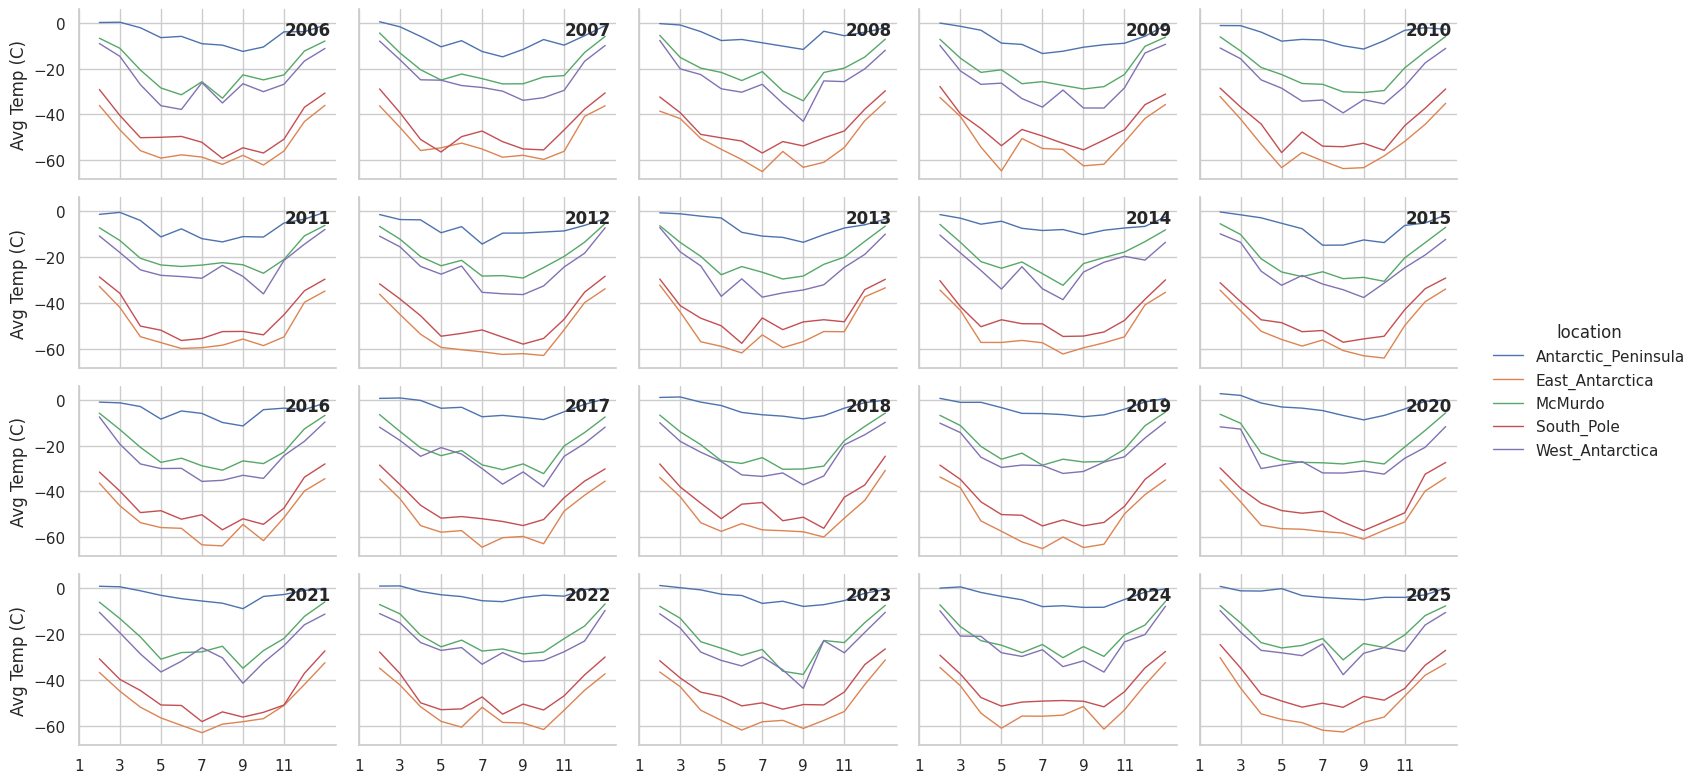

In [165]:
df['date'] = pd.to_datetime(df['date'])
monthly_avg = df.groupby([
    'location',
    df['date'].dt.year.rename('year'),
    df['date'].dt.month.rename('month')
])['temperature_2m_mean'].mean().reset_index()

plt.figure(figsize=(15, 3))
sns.set_theme(style = 'whitegrid')
g = sns.relplot(data = monthly_avg,
            x = 'month', y = 'temperature_2m_mean', col = 'year', hue = 'location',
            kind = 'line', linewidth=1, zorder=3,
            col_wrap=5, height=2, aspect=1.5, legend=True,
)
for year, ax in g.axes_dict.items():
    ax.text(.8, .85, year, transform=ax.transAxes, fontweight="bold")
x = monthly_avg['month'].unique()
plt.xticks(range(0, len(x), 2), x[::2])

g.set_titles("")
g.set_axis_labels("", "Avg Temp (C)")
g.tight_layout()

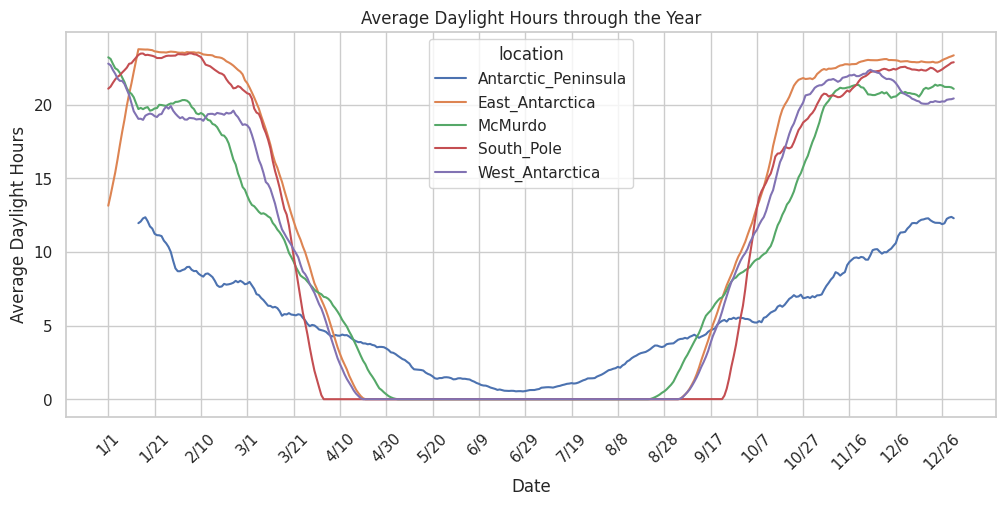

In [166]:
daylight_avg = df.groupby([
    'location',
    df['date'].dt.month.rename('month'),
    df['date'].dt.day.rename('day')
])['sunshine_duration'].mean().reset_index()
daylight_avg['sunshine_duration_hrs'] = (daylight_avg['sunshine_duration'] / 3600).round(2)
daylight_avg['sunshine_duration_hrs'] = daylight_avg['sunshine_duration_hrs'].rolling(14).mean()
daylight_avg['full_date'] = daylight_avg['month'].astype(str) + '/' + daylight_avg['day'].astype(str)

plt.figure(figsize=(12, 5))
sns.set_theme(style = 'whitegrid')
plt.title('Average Daylight Hours through the Year')
plt.xlabel('Date')
plt.ylabel('Average Daylight Hours')
x = daylight_avg['full_date'].unique()
plt.xticks(range(0, len(x), 20), x[::20], rotation=45)

g = sns.lineplot(data = daylight_avg, x = 'full_date', y = 'sunshine_duration_hrs', hue = 'location')

In [167]:
dirs = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
df['wind_direction'] = df['wind_direction_10m_dominant'].apply(lambda d: dirs[int((d % 360 + 11.25) // 22.5) % 16])

wind_data = df.groupby(['location', 'wind_direction']).agg(
    freq=('wind_direction', 'size'),
    speed=('wind_speed_10m_max', 'mean')
).reset_index()

locs = wind_data['location'].unique()
fig = make_subplots(
    rows=2, cols=3,
    subplot_titles=locs,
    specs=[[{'type': 'polar'}]*3]*2
)

for idx, loc in enumerate(locs):
    df_loc = wind_data[wind_data['location'] == loc]
    fig.add_trace(
        go.Barpolar(
            r=df_loc['freq'], theta=df_loc['wind_direction'], name=loc,
            marker=dict(color=df_loc['speed'], colorscale='Viridis', showscale=(idx == 0))
        ),
        row=(idx // 3) + 1, col=(idx % 3) + 1
    )

fig.update_layout(
    height=750,
    title_text="Wind Frequency and Average Speed",
    title_x=0.5,
    showlegend=False,
    margin=dict(t=100, b=50, l=50, r=50)
)

fig.update_annotations(yshift=15)

fig.update_polars(
    angularaxis=dict(
        direction="clockwise",
        rotation=90,
        categoryarray=dirs,
        categoryorder="array"
    )
)

fig.show()

<Figure size 1500x300 with 0 Axes>

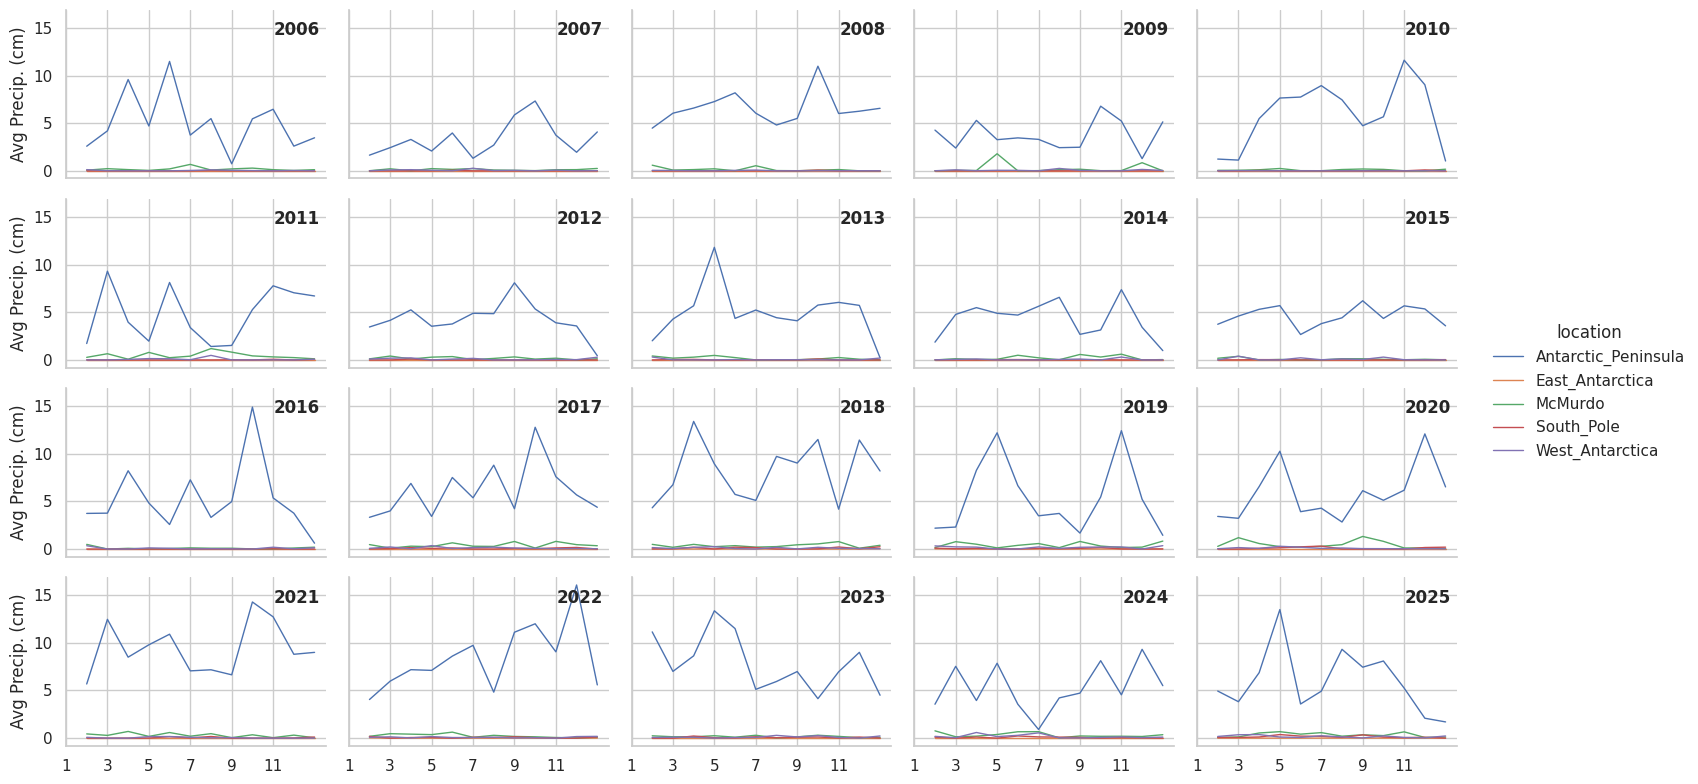

In [168]:
df['date'] = pd.to_datetime(df['date'])
monthly_avg = df.groupby([
    'location',
    df['date'].dt.year.rename('year'),
    df['date'].dt.month.rename('month')
])['precipitation_sum'].mean().reset_index()

plt.figure(figsize=(15, 3))
sns.set_theme(style = 'whitegrid')
g = sns.relplot(data = monthly_avg,
            x = 'month', y = 'precipitation_sum', col = 'year', hue = 'location',
            kind = 'line', linewidth=1, zorder=3,
            col_wrap=5, height=2, aspect=1.5, legend=True,
)
for year, ax in g.axes_dict.items():
    ax.text(.8, .85, year, transform=ax.transAxes, fontweight="bold")
x = monthly_avg['month'].unique()
plt.xticks(range(0, len(x), 2), x[::2])

g.set_titles("")
g.set_axis_labels("", "Avg Precip. (cm)")
g.tight_layout()